# 2D calibration: reference spectral profile

The default loads target profile 1 for inspection. Set RECOMPUTE_PROFILE=True to recompute the target Green kernel, then SAVE_DATA=True to save it under a new id. For a new geometry, use geometry_creation.ipynb first.

**Setup:** from the repository root, run `conda env create -f environment.yml` then `conda activate single-photon-renorm`, then `jupyter lab`. Select that Python environment as the kernel. The first cell also supports running directly from the checkout.

**How to use:** run cells from top to bottom. Parameters are grouped before the simulation or plotting cells. Figures display inline; `SAVE_FIGURES=False` prevents overwriting exported PDFs. Units: ħ = c = 1. See `guide_utilisation.pdf` at the repository root for notation and the calibration workflow.


# Generate a 2D spectral target profile

This notebook builds the component-resolved profile `F_ljk = d_j G_jk(omega_l) d_k` used by `make_2d_config(..., correction=True)`.

In [1]:
RECOMPUTE_PROFILE = False
SAVE_DATA = False
SAVE_FIGURES = True  # Set True to export the figures to results/fig.

# Run from the repository root or any of its subdirectories.
import sys
from pathlib import Path
project_root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                     if (p / "src" / "experiment.py").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Open Jupyter inside the single_photon_code checkout; see README.md.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
benchmark_root = project_root / "waveguide_model"
setup_root = project_root / "2d_setup"


import matplotlib.pyplot as plt
plt.rcParams.update({"text.usetex": True, "font.family": "serif",
                     "font.serif": ["Computer Modern Roman"]})
import numpy as np
resol = 160

import pandas as pd
from importlib import import_module


from importlib import import_module
load_geometry_by_id = import_module("2d_setup.geometry").load_geometry_by_id
plot_geometry = import_module("2d_setup.geometry").plot_geometry
generate_target_profile = import_module("2d_setup.bare_param").generate_target_profile
save_target_profile_csv = import_module("2d_setup.database").save_target_profile_csv
target_profile_path = import_module("2d_setup.database").target_profile_path

Choose the geometry used to compute the spectral target profile.

In [2]:
geometry_id = 5
geometry = load_geometry_by_id(geometry_id)

L1, L2 = geometry["lengths"]
N_A = geometry["N_A"]
atom_positions = geometry["atom_positions"]

print(f"Loaded geometry: {geometry['path'].name}")
print(f"lengths={geometry['lengths']}, N_A={N_A}, N_layer={geometry['N_layer']}, kind={geometry['kind']}")

Loaded geometry: geometry_id5.csv
lengths=[5. 5.], N_A=10, N_layer=1, kind=slab


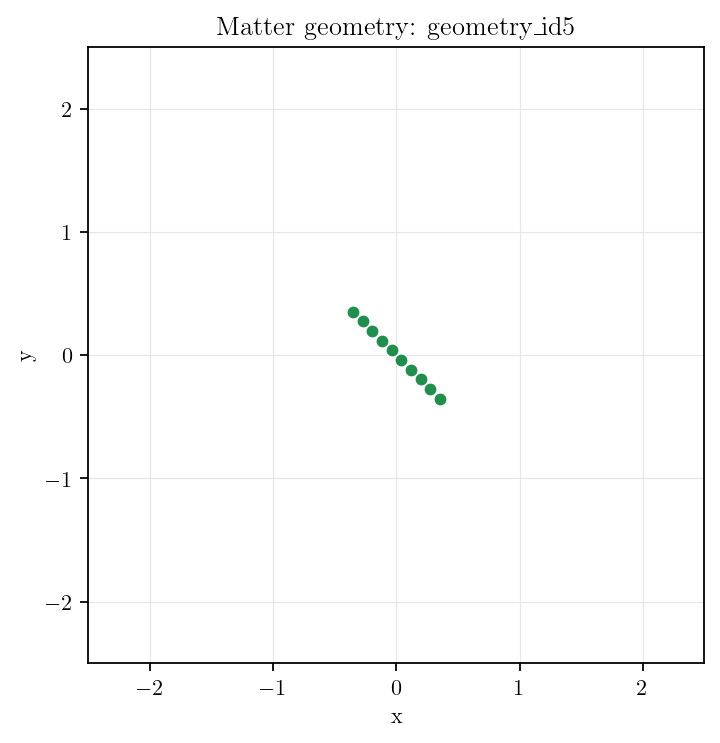

In [3]:
# Font sizes in points for this figure; edit these values directly.
plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
    "legend.title_fontsize": 13,
})

fig, ax = plt.subplots(figsize=(5, 5), dpi=resol)
ax.scatter(
    atom_positions[:, 0],
    atom_positions[:, 1],
    s=34,
    color="#1f8f4d",
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)
ax.set_xlim(-L1 / 2, L1 / 2)
ax.set_ylim(-L2 / 2, L2 / 2)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(color="0.9", linewidth=0.5)
ax.set_title(f"Matter geometry: {geometry['label']}")
plt.show()

Set the target atom parameters and the reference frequency data. `Omega_A` and `d_A` are arrays with one entry per atom.

In [4]:
Omega_A = 10 * np.pi * np.ones(geometry["N_A"])
d_A = np.ones(geometry["N_A"], dtype=float)

reference_cutoffs = {
    "Omega_min": 0 * np.pi,
    "Omega_max": 20 * np.pi,
}

nb_omega_values = 200
omega_values = np.linspace(0.1 * np.pi, 19.9 * np.pi, nb_omega_values)

radius_cache_decimals = 4 if geometry["kind"] == "slab" else 12
print(f"N_omega = {len(omega_values)}")
print(f"N_spectral_entries = {len(omega_values) * geometry['N_A'] ** 2}")
print(f"radius_cache_decimals = {radius_cache_decimals}")

N_omega = 200
N_spectral_entries = 20000
radius_cache_decimals = 4


In [5]:
if RECOMPUTE_PROFILE:
    target_profile = generate_target_profile(
        omega_values,
        atom_positions=atom_positions,
        Omega_j=Omega_A,
        d_j=d_A,
        reference_cutoffs=reference_cutoffs,
        id_geom=geometry_id,
        epsabs=1e-7,
        epsrel=1e-7,
        cache_decimals=radius_cache_decimals,
        progress=True,
    )

    target_profile.head()
else:
    read_metadata = import_module("2d_setup.database").read_metadata
    target_profile = pd.read_csv(target_profile_path(1), comment="#")
    target_profile.attrs["metadata"] = read_metadata(target_profile_path(1))
    print("Loaded bundled target_profile_id1.csv")

Loaded bundled target_profile_id1.csv


In [6]:
if SAVE_DATA and RECOMPUTE_PROFILE:
    output_path = target_profile_path()
    save_target_profile_csv(target_profile, output_path)

    print(f"Saved target profile to: {output_path}")
    print("make_2d_config(correction=True) will find bare params generated from this profile.")
else:
    print("No target profile written. Enable recomputation and SAVE_DATA to save a new profile.")

No target profile written. Enable recomputation and SAVE_DATA to save a new profile.
